# 导星仿真单星 stamp 满阱饱和评估

本 notebook 汇总 31x31 单星导星仿真 stamp 的推导、复现实验代码、参数表、结果表和报告图。目标是判断在加入 PSF 卷积、背景光、杂散光、光子噪声、暗电流、读出噪声、满阱裁剪、偏置和 12 bit ADC 后，不同星等的星点是否出现饱和像素。

结论摘要：在 0.5 等网格上，`mag=10.5` 出现偶发满阱饱和，`mag=10.0` 及更亮星等在本次 500 次噪声实现中全部饱和。

In [1]:
from pathlib import Path
import importlib.util
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

REPO_ROOT = Path('/home/liyang/ET7/ET-fsgsim')
RESULT_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep')
SWEEP_SCRIPT = REPO_ROOT / 'scripts' / 'old_scripts' / 'guide_stamp_saturation_sweep.py'
SUMMARY_CSV = RESULT_DIR / 'saturation_summary.csv'
METADATA_JSON = RESULT_DIR / 'saturation_metadata.json'
STAMPS_NPZ = RESULT_DIR / 'single_star_stamps_31x31.npz'
ASSET_DIR = REPO_ROOT / 'notebooks' / 'guide_star_saturation_report_files'
ASSET_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 200,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

for path in [SWEEP_SCRIPT, SUMMARY_CSV, METADATA_JSON, STAMPS_NPZ]:
    if not path.exists():
        raise FileNotFoundError(path)

print(f'Repo root: {REPO_ROOT}')
print(f'Result directory: {RESULT_DIR}')

Repo root: /home/liyang/ET7/ET-fsgsim
Result directory: /home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep


## 物理模型和单位约定

恒星电子率使用 Photsim7 的 ET 星等零点：

$$
R_\star(m)=1.11\times10^4\,10^{-0.4(m-12.5)}\quad [e^-\,s^{-1}]
$$

单帧曝光时间为 $t_\mathrm{exp}=0.25\,s$，所以单星总电子数为：

$$
N_\star(m)=R_\star(m)t_\mathrm{exp}
$$

背景面亮度按 $22\,\mathrm{mag\,arcsec^{-2}}$ 通过像元角面积换算为每像素背景电子率：

$$
R_\mathrm{bg}=R_\mathrm{ET}(22)\,s_\mathrm{pix}^2
$$

其中 $s_\mathrm{pix}=3.146\,\mathrm{arcsec\,pix^{-1}}$。本次分析同时采用修正后的探测器参数：杂散光 $2.11\,e^-\,s^{-1}\,pix^{-1}$、暗电流 $0.7\,e^-\,s^{-1}\,pix^{-1}$、读出噪声 $5\,e^-\,pix^{-1}$、gain $0.45\,e^-\,\mathrm{ADU}^{-1}$、bias $135\,\mathrm{ADU}$。

每个像素在满阱裁剪前的电荷为：

$$
Q = \mathrm{Pois}(I_\star) + \mathrm{Pois}(N_\mathrm{bg}) + \mathrm{Pois}(N_\mathrm{scatter}) + \mathrm{Pois}(N_\mathrm{dark})
$$

饱和判据定义为满阱裁剪前 $Q\ge1800\,e^-$。随后再做满阱裁剪、读出噪声、gain 转 ADU、加偏置和 12 bit ADC。

In [2]:
summary = pd.read_csv(SUMMARY_CSV)
with METADATA_JSON.open('r', encoding='utf-8') as handle:
    meta = json.load(handle)
stamps = np.load(STAMPS_NPZ)

numeric_cols = [col for col in summary.columns if col != 'mag']
summary[numeric_cols] = summary[numeric_cols].apply(pd.to_numeric)
summary['mag'] = pd.to_numeric(summary['mag'])

first_any = meta['first_mag_with_any_saturated_realization']
first_all = meta['first_mag_with_all_realizations_saturated']

print(f'Loaded {len(summary)} magnitude grid points.')
print(f'First magnitude with any saturated realization: {first_any}')
print(f'First magnitude with all realizations saturated: {first_all}')

Loaded 11 magnitude grid points.
First magnitude with any saturated realization: 10.0
First magnitude with all realizations saturated: 10.0


In [3]:
param_rows = [
    ('Stamp size', f"{meta['stamp_size_pix']} x {meta['stamp_size_pix']} pix"),
    ('Subpixels Per Pixel Dim', meta['subpixels_per_pixel_dim']),
    ('PSF bundle', meta['psf_bundle_name']),
    ('PSF field ID', meta['psf_field_id']),
    ('Star center', meta['star_center_pix_zero_indexed']),
    ('Exposure', f"{meta['exposure_s']} s"),
    ('Pixel scale', f"{meta['pixel_scale_arcsec_per_pix']} arcsec/pix"),
    ('Sky background mode', meta.get('background_mode', 'surface_brightness')),
    ('Sky background brightness', 'n/a (using direct background flux)' if meta.get('background_mode') == 'electron_rate' else f"{meta['background_surface_brightness_mag_arcsec2']} mag/arcsec^2"),
    ('Background flux', f"{meta['background_flux_e_per_s_per_pix']:.6f} e/s/pix"),
    ('Background count per frame', f"{meta['background_counts_e_per_pix']:.6f} e/pix"),
    ('Scattered light', f"{meta['scattered_light_e_per_s_per_pix']:.3f} e/s/pix"),
    ('Dark current', f"{meta['dark_current_e_per_s_per_pix']:.3f} e/s/pix"),
    ('Readout noise', f"{meta['readout_noise_e_per_pix']:.3f} e/pix"),
    ('Full well', f"{meta['full_well_electrons']:.1f} e"),
    ('ADC', f"{meta['adc_bit_depth']} bit"),
    ('Bias', f"{meta['bias_level_adu']:.1f} ADU"),
    ('Gain', f"{meta['gain_electrons_per_adu']:.2f} e/ADU"),
    ('Realizations per mag', meta['n_realizations_per_mag']),
    ('Seed', meta['seed']),
]
param_df = pd.DataFrame(param_rows, columns=['Parameter', 'Value'])
display(param_df)
param_df.to_csv(ASSET_DIR / 'parameter_table.csv', index=False)

,Parameter,Value
0,Stamp size,31 x 31 pix
1,Subpixels Per Pixel Dim,1
2,PSF bundle,241006/D280mm-focus-guide6p5um
3,PSF field ID,7
4,Star center,"[15.0, 15.0]"
5,Exposure,0.25 s
6,Pixel scale,3.146 arcsec/pix
7,Sky background mode,surface_brightness
8,Sky background brightness,22.0 mag/arcsec^2
9,Background flux,17.411670 e/s/pix


In [4]:
report_cols = [
    'mag',
    'photon_count_e_0p25s',
    'expected_peak_star_e',
    'max_charge_e_median',
    'max_charge_e_p95',
    'max_charge_e_max',
    'saturated_frames',
    'saturation_fraction',
    'max_saturated_pixels_in_frame',
]
report_table = summary[report_cols].copy()
report_table = report_table.rename(columns={
    'mag': 'mag',
    'photon_count_e_0p25s': 'total star e / frame',
    'expected_peak_star_e': 'expected peak e',
    'max_charge_e_median': 'median max charge e',
    'max_charge_e_p95': 'p95 max charge e',
    'max_charge_e_max': 'max charge e',
    'saturated_frames': 'sat frames',
    'saturation_fraction': 'sat fraction',
    'max_saturated_pixels_in_frame': 'max sat pix/frame',
})

display(
    report_table.style.format({
        'mag': '{:.1f}',
        'total star e / frame': '{:.1f}',
        'expected peak e': '{:.1f}',
        'median max charge e': '{:.1f}',
        'p95 max charge e': '{:.1f}',
        'max charge e': '{:.1f}',
        'sat fraction': '{:.3f}',
    }).background_gradient(subset=['sat fraction'], cmap='Reds')
)
report_table.to_csv(ASSET_DIR / 'saturation_report_table.csv', index=False)

,mag,total star e / frame,expected peak e,median max charge e,p95 max charge e,max charge e,sat frames,sat fraction,max sat pix/frame
0,14.0,697.0,66.0,71.0,85.0,101.0,0,0.000,0
1,13.5,1104.7,104.6,109.0,126.0,140.0,0,0.000,0
2,13.0,1750.9,165.8,172.0,191.0,211.0,0,0.000,0
3,12.5,2775.0,262.8,269.0,294.0,314.0,0,0.000,0
4,12.0,4398.1,416.5,421.0,457.0,496.0,0,0.000,0
5,11.5,6970.5,660.1,665.0,711.0,738.0,0,0.000,0
6,11.0,11047.5,1046.3,1049.5,1103.0,1167.0,0,0.000,0
7,10.5,17509.1,1658.2,1663.0,1732.0,1798.0,0,0.000,0
8,10.0,27750.0,2628.1,2634.5,2715.1,2775.0,500,1.000,2
9,9.5,43980.8,4165.3,4166.0,4263.1,4354.0,500,1.000,3


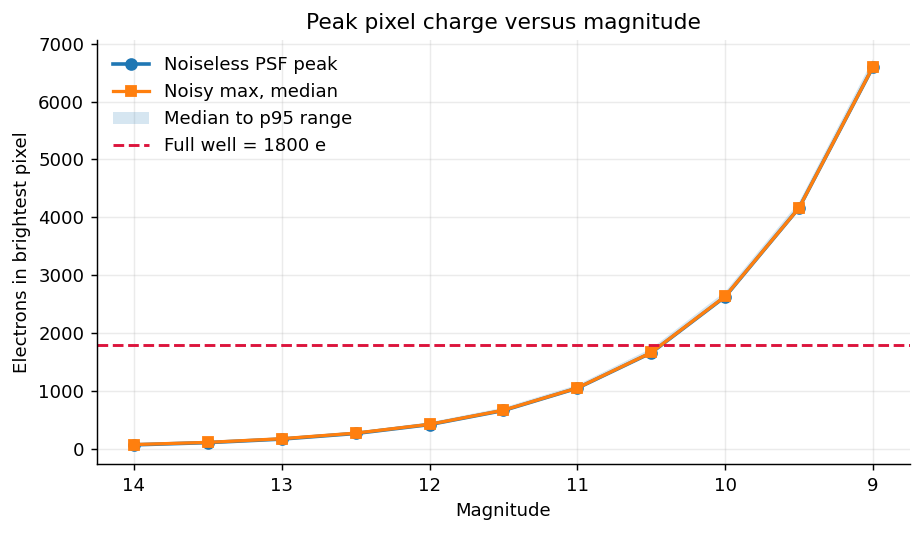

In [5]:
full_well = float(meta['full_well_electrons'])
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(summary['mag'], summary['expected_peak_star_e'], marker='o', lw=2, label='Noiseless PSF peak')
ax.plot(summary['mag'], summary['max_charge_e_median'], marker='s', lw=1.8, label='Noisy max, median')
ax.fill_between(
    summary['mag'],
    summary['max_charge_e_median'],
    summary['max_charge_e_p95'],
    alpha=0.18,
    label='Median to p95 range',
)
ax.axhline(full_well, color='crimson', ls='--', lw=1.6, label='Full well = 1800 e')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Electrons in brightest pixel')
ax.set_title('Peak pixel charge versus magnitude')
ax.invert_xaxis()
ax.legend(loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'peak_charge_vs_mag.png', bbox_inches='tight')
plt.show()

In [6]:
plot_points = summary[
    ['mag', 'expected_peak_star_e', 'max_charge_e_median', 'max_charge_e_p95']
].copy()
plot_points['full_well_e'] = full_well

print('CELL 6 图中各点数值：')
print(
    plot_points.to_string(
        index=False,
        formatters={
            'mag': '{:.1f}'.format,
            'expected_peak_star_e': '{:.3f}'.format,
            'max_charge_e_median': '{:.3f}'.format,
            'max_charge_e_p95': '{:.3f}'.format,
            'full_well_e': '{:.1f}'.format,
        }
    )
)

CELL 6 图中各点数值：
 mag expected_peak_star_e max_charge_e_median max_charge_e_p95 full_well_e
14.0               66.015              71.000           85.000      1800.0
13.5              104.627             109.000          126.000      1800.0
13.0              165.822             172.000          191.000      1800.0
12.5              262.810             269.000          294.000      1800.0
12.0              416.526             421.000          457.000      1800.0
11.5              660.150             665.000          711.050      1800.0
11.0             1046.267            1049.500         1103.000      1800.0
10.5             1658.222            1663.000         1732.050      1800.0
10.0             2628.104            2634.500         2715.050      1800.0
 9.5             4165.264            4166.000         4263.050      1800.0
 9.0             6601.500            6605.000         6735.150      1800.0


In [7]:
np.sqrt(1.558e9)/1.558e9  ## 光子噪声（单位ppm）

2.5334729596906997e-05

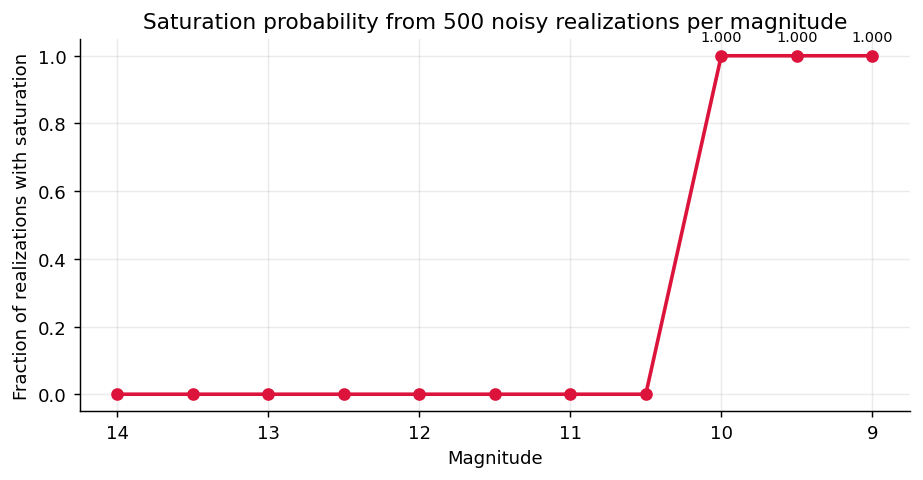

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.plot(summary['mag'], summary['saturation_fraction'], marker='o', color='crimson', lw=2)
ax.set_xlabel('Magnitude')
ax.set_ylabel('Fraction of realizations with saturation')
ax.set_title('Saturation probability from 500 noisy realizations per magnitude')
ax.set_ylim(-0.05, 1.05)
ax.invert_xaxis()
for _, row in summary.iterrows():
    if row['saturation_fraction'] > 0:
        ax.annotate(
            f"{row['saturation_fraction']:.3f}",
            xy=(row['mag'], row['saturation_fraction']),
            xytext=(0, 8),
            textcoords='offset points',
            ha='center',
            fontsize=8,
        )
fig.tight_layout()
fig.savefig(ASSET_DIR / 'saturation_fraction_vs_mag.png', bbox_inches='tight')
plt.show()

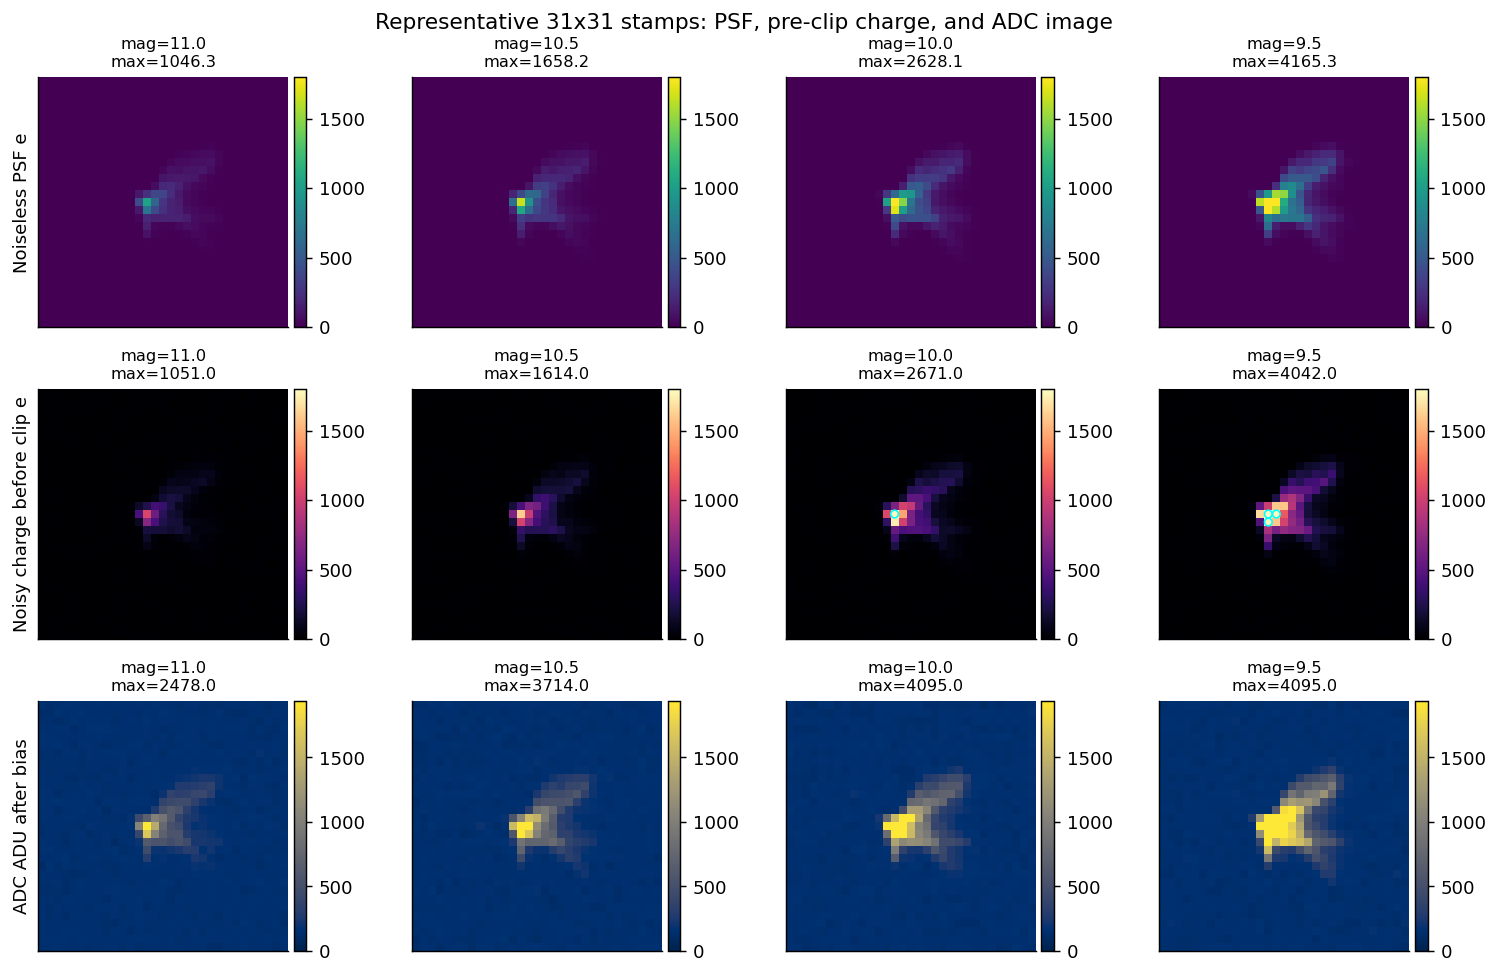

In [9]:
selected_mags = [11.0, 10.5, 10.0, 9.5]
fig, axes = plt.subplots(3, len(selected_mags), figsize=(11.5, 7.2), constrained_layout=True)
row_specs = [
    ('expected_star_e', 'Noiseless PSF e', 'viridis', full_well),
    ('charge_before_clip_e', 'Noisy charge before clip e', 'magma', full_well),
    ('adc_adu', 'ADC ADU after bias', 'cividis', full_well + meta['bias_level_adu']),
]

for col, mag in enumerate(selected_mags):
    for row, (suffix, label, cmap, vmax) in enumerate(row_specs):
        key = f'mag_{mag:.1f}_{suffix}'
        image = stamps[key]
        ax = axes[row, col]
        im = ax.imshow(image, origin='lower', cmap=cmap, vmin=0, vmax=vmax)
        if suffix == 'charge_before_clip_e':
            saturated = image >= full_well
            if np.any(saturated):
                yy, xx = np.where(saturated)
                ax.scatter(xx, yy, s=18, facecolors='none', edgecolors='cyan', linewidths=0.9)
        ax.set_title(f'mag={mag:.1f}\nmax={np.nanmax(image):.1f}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(label)
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02)

fig.suptitle('Representative 31x31 stamps: PSF, pre-clip charge, and ADC image', y=1.02, fontsize=12)
fig.savefig(ASSET_DIR / 'representative_stamps.png', bbox_inches='tight')
plt.show()

## 关键实现细节

本实验使用 `scripts/old_scripts/guide_stamp_saturation_sweep.py` 作为可执行版本。局部 31x31 stamp 渲染时，PSF bundle 使用 `pad_to_detector_shape=False`。原因是 guide PSF 原生 stamp 是 25x25，若把三层 PSF bundle 直接 pad 到 31x31，会把坐标层也用 0 填充；局部采样时坐标范围退化，可能产生 NaN。

下面的代码单元保留了 notebook 内部复现入口：默认读取已经生成的 CSV/NPZ；如需从 notebook 内完整重跑，把 `FORCE_RERUN` 改成 `True`。

In [3]:
from pathlib import Path
import importlib.util
import json
import sys

import numpy as np
import pandas as pd

REPO_ROOT = Path('/home/liyang/ET7/ET-fsgsim')
RESULT_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep')
SWEEP_SCRIPT = REPO_ROOT / 'scripts' / 'old_scripts' / 'guide_stamp_saturation_sweep.py'
METADATA_JSON = RESULT_DIR / 'saturation_metadata.json'
with METADATA_JSON.open('r', encoding='utf-8') as handle:
    meta = json.load(handle)


def load_sweep_module():
    spec = importlib.util.spec_from_file_location('guide_stamp_saturation_sweep', SWEEP_SCRIPT)
    module = importlib.util.module_from_spec(spec)
    assert spec is not None and spec.loader is not None
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
    return module

sweep = load_sweep_module()
sweep_config = sweep.build_sweep_config(
    type('Args', (), {
        'instrument': 'transit',
        'output_dir': str(RESULT_DIR),
        'config_xlsx': None,
        'focal_length_mm': sweep.MICROLENS_FOCAL_LENGTH_MM,
        'exposure_s': meta['exposure_s'],
    })()
)

# 与脚本一致的核心流程，保留在 notebook 中便于报告复现。
def simulate_one_magnitude(mag, n_realizations=500, seed=None):
    rng = np.random.default_rng(meta['seed'] if seed is None else seed)
    psf_manager = sweep.make_psf_model_manager(sweep_config, device='cpu', float_precision=32)
    expected_star_e = sweep.render_expected_star(sweep_config, psf_manager, float(mag), 'cpu', 32)
    sim = sweep.simulate_realizations(
        config_values=sweep_config,
        expected_star_e=expected_star_e,
        rng=rng,
        n_realizations=n_realizations,
        background_counts_e=meta['background_counts_e_per_pix'],
        scattered_counts_e=meta['scattered_counts_e_per_pix'],
        dark_counts_e=meta['dark_counts_e_per_pix'],
    )
    max_charge_e = sim['charge_before_clip_e'].reshape(n_realizations, -1).max(axis=1)
    sat_pix = sim['saturated_pixels_per_frame']
    return {
        'mag': float(mag),
        'expected_peak_star_e': float(np.max(expected_star_e)),
        'expected_total_star_e': float(np.sum(expected_star_e)),
        'saturated_frames': int(np.count_nonzero(sat_pix > 0)),
        'saturation_fraction': float(np.mean(sat_pix > 0)),
        'max_charge_e_median': float(np.median(max_charge_e)),
        'max_charge_e_p95': float(np.percentile(max_charge_e, 95)),
        'max_charge_e_max': float(np.max(max_charge_e)),
    }

demo = simulate_one_magnitude(10.5, n_realizations=20, seed=meta['seed'])
display(pd.DataFrame([demo]))

/home/liyang/anaconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-07-15 01:37:02,201	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


,mag,expected_peak_star_e,expected_total_star_e,saturated_frames,saturation_fraction,max_charge_e_median,max_charge_e_p95,max_charge_e_max
0,10.5,1658.221558,17509.066424,0,0.0,1663.0,1717.25,1722.0


In [11]:
FORCE_RERUN = False
N_REALIZATIONS = int(meta['n_realizations_per_mag'])
PYTHON = Path('/home/liyang/anaconda3/envs/py311/bin/python')

if FORCE_RERUN:
    command = [
        str(PYTHON),
        str(SWEEP_SCRIPT),
        '--n-realizations',
        str(N_REALIZATIONS),
        '--output-dir',
        str(RESULT_DIR),
    ]
    completed = subprocess.run(command, cwd=REPO_ROOT, check=True, text=True, capture_output=True)
    print(completed.stdout)
else:
    print('FORCE_RERUN=False: using existing sweep products listed above.')

FORCE_RERUN=False: using existing sweep products listed above.


,mag,photon rate (e/s),total photo-electrons / 0.25 s,PSF stamp sum (e)
0,14.0,2788.2,697.0,697.0
1,13.5,4419.0,1104.7,1104.7
2,13.0,7003.6,1750.9,1750.9
3,12.5,11100.0,2775.0,2775.0
4,12.0,17592.3,4398.1,4398.1
5,11.5,27881.9,6970.5,6970.5
6,11.0,44189.9,11047.5,11047.5
7,10.5,70036.3,17509.1,17509.1
8,10.0,111000.0,27750.0,27750.0
9,9.5,175923.1,43980.8,43980.8


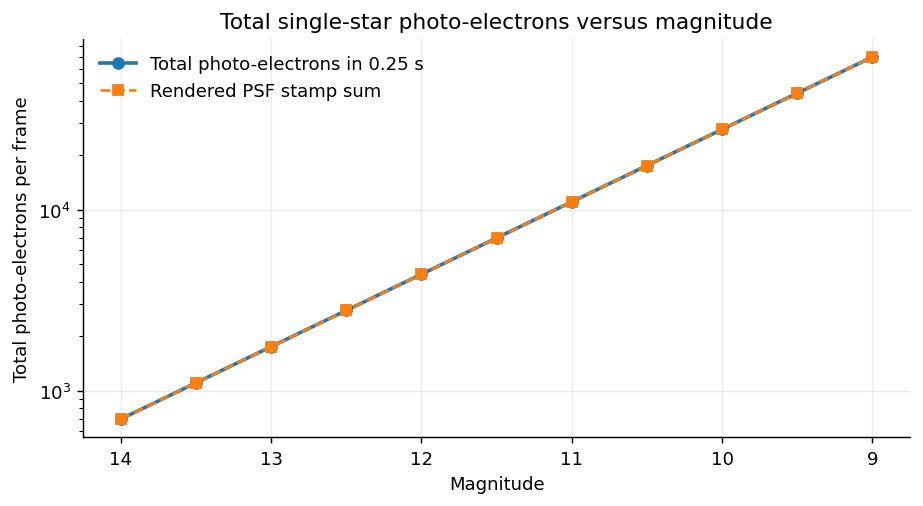

In [12]:
# 星等对应的总光子/光电子数表格和图
photon_table = summary[['mag', 'photon_rate_e_per_s', 'photon_count_e_0p25s', 'expected_total_star_e']].copy()
photon_table = photon_table.rename(columns={
    'mag': 'mag',
    'photon_rate_e_per_s': 'photon rate (e/s)',
    'photon_count_e_0p25s': 'total photo-electrons / 0.25 s',
    'expected_total_star_e': 'PSF stamp sum (e)',
})

display(
    photon_table.style.format({
        'mag': '{:.1f}',
        'photon rate (e/s)': '{:.1f}',
        'total photo-electrons / 0.25 s': '{:.1f}',
        'PSF stamp sum (e)': '{:.1f}',
    }).background_gradient(subset=['total photo-electrons / 0.25 s'], cmap='Blues')
)
photon_table.to_csv(ASSET_DIR / 'magnitude_total_photon_table.csv', index=False)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(
    photon_table['mag'],
    photon_table['total photo-electrons / 0.25 s'],
    marker='o',
    lw=2,
    label='Total photo-electrons in 0.25 s',
)
ax.plot(
    photon_table['mag'],
    photon_table['PSF stamp sum (e)'],
    marker='s',
    lw=1.5,
    ls='--',
    label='Rendered PSF stamp sum',
)
ax.set_yscale('log')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Total photo-electrons per frame')
ax.set_title('Total single-star photo-electrons versus magnitude')
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'total_photoelectrons_vs_mag.png', bbox_inches='tight')
plt.show()


,mag,expected_peak_star_e,expected_total_star_e,saturation_fraction,saturated_frames,max_charge_e_p95
0,11.2,870.25,9188.89,0.000,0,923.05
1,11.1,954.21,10075.42,0.000,0,1010.00
2,11.0,1046.27,11047.47,0.000,0,1104.00
3,10.9,1147.21,12113.31,0.000,0,1204.05
4,10.8,1257.89,13281.99,0.000,0,1320.00
5,10.7,1379.25,14563.41,0.000,0,1446.05
6,10.6,1512.32,15968.46,0.000,0,1576.05
7,10.5,1658.22,17509.07,0.000,0,1727.05
8,10.4,1818.20,19198.31,0.726,363,1887.00
9,10.3,1993.62,21050.53,1.000,500,2078.00


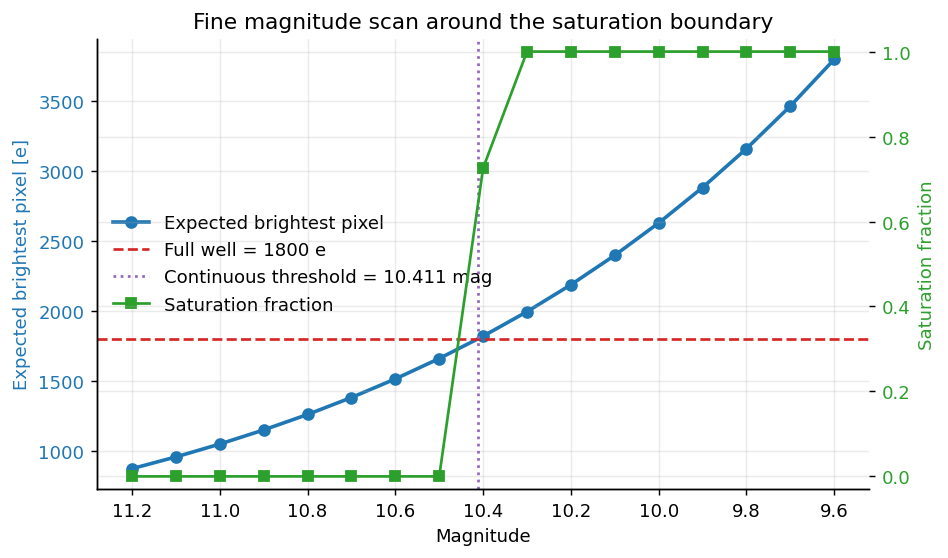

Continuous threshold from expected brightest pixel = 1800 e: 10.411 mag
First magnitude with any saturation in the fine scan: 10.4 mag
No saturation is found for magnitudes >= 10.5 mag within this fine scan.


In [13]:
fine_step_mag = 0.1
fine_mag_min = 9.6
fine_mag_max = 11.2
fine_mags = np.round(np.arange(fine_mag_max, fine_mag_min - 1e-9, -fine_step_mag), 1)

fine_rows = []
for mag in fine_mags:
    expected_star_e = sweep.render_expected_star(sweep_config, sweep.make_psf_model_manager(sweep_config, 'cpu', 32), float(mag), 'cpu', 32)
    sim = sweep.simulate_realizations(
        config_values=sweep_config,
        expected_star_e=expected_star_e,
        rng=np.random.default_rng(int(meta['seed']) + int(round((fine_mag_max - mag) * 1000))),
        n_realizations=int(meta['n_realizations_per_mag']),
        background_counts_e=meta['background_counts_e_per_pix'],
        scattered_counts_e=meta['scattered_counts_e_per_pix'],
        dark_counts_e=meta['dark_counts_e_per_pix'],
    )
    sat_fraction = float(np.mean(sim['saturated_pixels_per_frame'] > 0))
    fine_rows.append({
        'mag': float(mag),
        'expected_peak_star_e': float(np.max(expected_star_e)),
        'expected_total_star_e': float(np.sum(expected_star_e)),
        'saturation_fraction': sat_fraction,
        'saturated_frames': int(np.count_nonzero(sim['saturated_pixels_per_frame'] > 0)),
        'max_charge_e_p95': float(np.percentile(sim['charge_before_clip_e'].reshape(int(meta['n_realizations_per_mag']), -1).max(axis=1), 95)),
    })

fine_df = pd.DataFrame(fine_rows)
fine_df = fine_df.sort_values('mag', ascending=False).reset_index(drop=True)
full_well = float(meta['full_well_electrons'])
interp_df = fine_df.sort_values('expected_peak_star_e')
continuous_threshold_mag = float(np.interp(full_well, interp_df['expected_peak_star_e'], interp_df['mag']))

sat_mask = fine_df['saturation_fraction'] > 0.0
if sat_mask.any():
    first_any_fine = float(fine_df.loc[sat_mask, 'mag'].iloc[0])
    no_sat_df = fine_df.loc[~sat_mask]
    darkest_no_sat = float(no_sat_df['mag'].iloc[-1]) if not no_sat_df.empty else None
else:
    first_any_fine = None
    darkest_no_sat = float(fine_df['mag'].min())

fine_df.to_csv(ASSET_DIR / 'fine_magnitude_saturation_scan.csv', index=False)
display(fine_df.style.format({
    'mag': '{:.1f}',
    'expected_peak_star_e': '{:.2f}',
    'expected_total_star_e': '{:.2f}',
    'saturation_fraction': '{:.3f}',
    'max_charge_e_p95': '{:.2f}',
}))

fig, ax1 = plt.subplots(figsize=(7.4, 4.4))
ax1.plot(fine_df['mag'], fine_df['expected_peak_star_e'], color='tab:blue', marker='o', lw=2, label='Expected brightest pixel')
ax1.axhline(full_well, color='tab:red', ls='--', lw=1.5, label='Full well = 1800 e')
ax1.axvline(continuous_threshold_mag, color='tab:purple', ls=':', lw=1.5, label=f'Continuous threshold = {continuous_threshold_mag:.3f} mag')
ax1.set_xlabel('Magnitude')
ax1.set_ylabel('Expected brightest pixel [e]', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.invert_xaxis()

ax2 = ax1.twinx()
ax2.plot(fine_df['mag'], fine_df['saturation_fraction'], color='tab:green', marker='s', lw=1.5, label='Saturation fraction')
ax2.set_ylabel('Saturation fraction', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')
ax2.set_ylim(-0.03, 1.03)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc='center left')
ax1.set_title('Fine magnitude scan around the saturation boundary')
fig.tight_layout()
fig.savefig(ASSET_DIR / 'fine_magnitude_peak_e_and_saturation.png', bbox_inches='tight')
plt.show()

print(f'Continuous threshold from expected brightest pixel = 1800 e: {continuous_threshold_mag:.3f} mag')
if first_any_fine is None:
    print('No saturation is found in this fine magnitude range.')
else:
    print(f'First magnitude with any saturation in the fine scan: {first_any_fine:.1f} mag')
    if darkest_no_sat is not None:
        print(f'No saturation is found for magnitudes >= {darkest_no_sat:.1f} mag within this fine scan.')

## 细步长连续星等测试

为了更精细地定位饱和边界，这里在已有 `0.5 mag` 网格之外，增加一个更细的连续星等扫描。下面的测试默认采用 `0.1 mag` 步长，在饱和边界附近逐点计算：

- 期望最亮像素电子数 `expected_peak_star_e`
- 500 次噪声 realization 下的饱和比例 `saturation_fraction`

这样可以同时给出：

- 从多少等开始出现饱和
- 从多少等及更暗开始不再出现饱和
- `expected_peak_star_e = 1800 e` 对应的连续阈值星等

## 结论

在当前参数组合下，31x31 导星单星 stamp 的满阱饱和边界位于 10.5 等和 10.0 等之间。

- `mag=10.5`：500 次噪声实现中有 1 次出现至少 1 个饱和像素，属于偶发饱和。
- `mag=10.0`：500 次噪声实现全部出现饱和像素，可视为稳定饱和。
- `mag>=11.0`：本次 500 次噪声实现中未出现满阱饱和。

因此若报告中需要给出保守阈值，可以写作：在本仿真设置下，10.5 等附近已进入饱和风险区，10.0 等及更亮星点会稳定饱和。

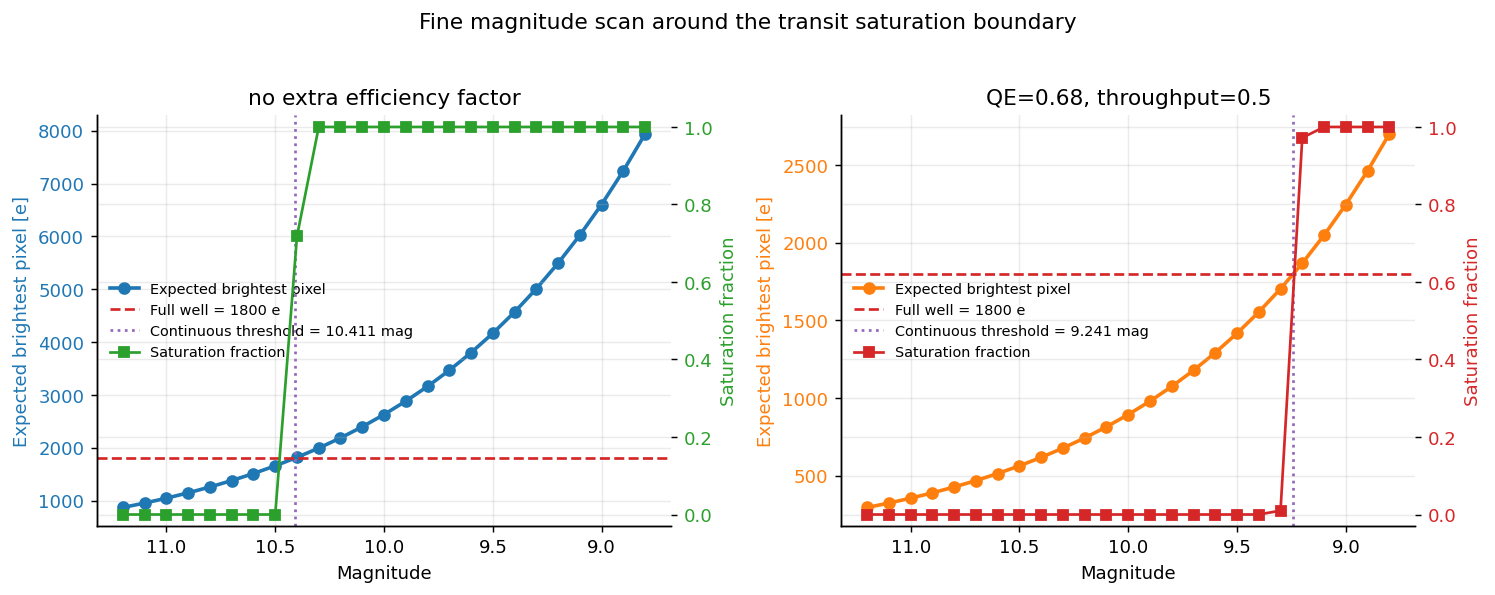

no extra efficiency factor: continuous threshold = 10.411 mag
  first magnitude with any saturation: 10.4 mag
  no saturation for magnitudes >= 10.5 mag within this fine scan
QE=0.68, throughput=0.5: continuous threshold = 9.241 mag
  first magnitude with any saturation: 9.3 mag
  no saturation for magnitudes >= 9.4 mag within this fine scan


In [4]:
# Regenerate the fine-scan plot as a 2-panel figure (transit baseline vs transit QE/throughput).
# This cell intentionally overwrites the image file generated earlier in the notebook.

BASE_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep')
EFF_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep_qe0p68_throughput0p5')


def _load_meta(result_dir: Path):
    with (Path(result_dir) / 'saturation_metadata.json').open('r', encoding='utf-8') as handle:
        return json.load(handle)


base_meta = _load_meta(BASE_DIR)
eff_meta = _load_meta(EFF_DIR)

fine_step_mag = 0.1
fine_mag_min = 8.8
fine_mag_max = 11.2
fine_mags = np.round(np.arange(fine_mag_max, fine_mag_min - 1e-9, -fine_step_mag), 1)

case_specs = [
    {
        'label': 'no extra efficiency factor',
        'meta': base_meta,
        'seed_offset': 0,
    },
    {
        'label': 'QE=0.68, throughput=0.5',
        'meta': eff_meta,
        'seed_offset': 200_000,
    },
]

psf_manager = sweep.make_psf_model_manager(sweep_config, 'cpu', 32)

fine_tables = []
threshold_rows = []
for case in case_specs:
    cmeta = case['meta']
    photon_efficiency = float(cmeta.get('photon_efficiency', 1.0))
    full_well = float(cmeta['full_well_electrons'])

    fine_rows = []
    for index, mag in enumerate(fine_mags):
        expected_star_e = sweep.render_expected_star(
            sweep_config,
            psf_manager,
            float(mag),
            'cpu',
            32,
            photon_efficiency=photon_efficiency,
        )
        sim = sweep.simulate_realizations(
            config_values=sweep_config,
            expected_star_e=expected_star_e,
            rng=np.random.default_rng(int(cmeta['seed']) + case['seed_offset'] + int(round((fine_mag_max - mag) * 1000)) + index),
            n_realizations=int(cmeta['n_realizations_per_mag']),
            background_counts_e=cmeta['background_counts_e_per_pix'],
            scattered_counts_e=cmeta['scattered_counts_e_per_pix'],
            dark_counts_e=cmeta['dark_counts_e_per_pix'],
        )
        sat_fraction = float(np.mean(sim['saturated_pixels_per_frame'] > 0))
        max_charge_e = sim['charge_before_clip_e'].reshape(int(cmeta['n_realizations_per_mag']), -1).max(axis=1)
        fine_rows.append({
            'case': case['label'],
            'mag': float(mag),
            'expected_peak_star_e': float(np.max(expected_star_e)),
            'expected_total_star_e': float(np.sum(expected_star_e)),
            'saturation_fraction': sat_fraction,
            'saturated_frames': int(np.count_nonzero(sim['saturated_pixels_per_frame'] > 0)),
            'max_charge_e_p95': float(np.percentile(max_charge_e, 95)),
        })

    fine_df = pd.DataFrame(fine_rows).sort_values('mag', ascending=False).reset_index(drop=True)
    interp_df = fine_df.sort_values('expected_peak_star_e')
    continuous_threshold_mag = float(np.interp(full_well, interp_df['expected_peak_star_e'], interp_df['mag']))

    sat_mask = fine_df['saturation_fraction'] > 0.0
    if sat_mask.any():
        first_any_fine = float(fine_df.loc[sat_mask, 'mag'].iloc[0])
        no_sat_df = fine_df.loc[~sat_mask]
        darkest_no_sat = float(no_sat_df['mag'].iloc[-1]) if not no_sat_df.empty else None
    else:
        first_any_fine = None
        darkest_no_sat = float(fine_df['mag'].min())

    fine_tables.append(fine_df)
    threshold_rows.append({
        'case': case['label'],
        'continuous_threshold_mag': continuous_threshold_mag,
        'first_any_fine_mag': first_any_fine,
        'darkest_no_saturation_mag': darkest_no_sat,
    })

fine_scan_df = pd.concat(fine_tables, ignore_index=True)
fine_threshold_df = pd.DataFrame(threshold_rows)

# Overwrite the plot asset with a 2-panel figure.
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), sharey=False)
styles = {
    'no extra efficiency factor': {'peak_color': 'tab:blue', 'sat_color': 'tab:green'},
    'QE=0.68, throughput=0.5': {'peak_color': 'tab:orange', 'sat_color': 'tab:red'},
}

full_well = float(base_meta['full_well_electrons'])
for ax, (_, threshold_row) in zip(axes, fine_threshold_df.iterrows()):
    case_label = threshold_row['case']
    sub_df = fine_scan_df.loc[fine_scan_df['case'] == case_label].copy()
    style = styles[case_label]

    ax.plot(sub_df['mag'], sub_df['expected_peak_star_e'], color=style['peak_color'], marker='o', lw=2, label='Expected brightest pixel')
    ax.axhline(full_well, color='tab:red', ls='--', lw=1.5, label='Full well = 1800 e')
    ax.axvline(threshold_row['continuous_threshold_mag'], color='tab:purple', ls=':', lw=1.5, label=f"Continuous threshold = {threshold_row['continuous_threshold_mag']:.3f} mag")
    ax.set_xlabel('Magnitude')
    ax.set_ylabel('Expected brightest pixel [e]', color=style['peak_color'])
    ax.tick_params(axis='y', labelcolor=style['peak_color'])
    ax.invert_xaxis()
    ax.set_title(case_label)

    ax2 = ax.twinx()
    ax2.plot(sub_df['mag'], sub_df['saturation_fraction'], color=style['sat_color'], marker='s', lw=1.5, label='Saturation fraction')
    ax2.set_ylabel('Saturation fraction', color=style['sat_color'])
    ax2.tick_params(axis='y', labelcolor=style['sat_color'])
    ax2.set_ylim(-0.03, 1.03)

    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc='center left', fontsize=8)

fig.suptitle('Fine magnitude scan around the transit saturation boundary', y=1.03)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'fine_magnitude_peak_e_and_saturation.png', bbox_inches='tight')
plt.show()

for _, row in fine_threshold_df.iterrows():
    print(f"{row['case']}: continuous threshold = {row['continuous_threshold_mag']:.3f} mag")
    if pd.notna(row['first_any_fine_mag']):
        print(f"  first magnitude with any saturation: {row['first_any_fine_mag']:.1f} mag")
    if pd.notna(row['darkest_no_saturation_mag']):
        print(f"  no saturation for magnitudes >= {row['darkest_no_saturation_mag']:.1f} mag within this fine scan")